In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import sys

In [2]:
'''
Choose your Lib path
(a pasta assets/lib fica dois niveis acima deste notebook)
'''
LIB_PATH = os.path.abspath(os.path.join('..', '..', 'lib'))
sys.path.append(LIB_PATH)

from myAudioProcessingLib import audioread, play
from myPlotLib import figureFormat
from mylibprocessing import SIGNALgenerate

In [3]:
# Definição de diretórios
SOUND_PATH = '../../sounds/' # Pasta de arquivos de som
SOUND_FILE = 'train.wav' # Sinal de entrada

In [4]:
# Carregamos o sinal
x, fs = audioread(os.path.join(SOUND_PATH, SOUND_FILE))

In [5]:
print(x.shape, fs)

(12880,) 8192


In [6]:
play(x, fs)

In [7]:
def COMPLEXmagnitude(z, version='sqrt'):
    if version == 'sqrt':
        '''
        Legnth of z
        '''
        mag = np.sqrt(np.real(z)**2 + np.imag(z)**2)
    elif version == 'abs':
        '''
        |z|
        '''
        mag = np.abs(z)
        
    return mag

def COMPLEXphase(z, version='arctan2', units='rad'):
    if version == 'arctan':
        '''
        arctan
        '''
        phi = np.arctan(np.imag(z) / (np.real(z) + 1e-12))
    elif version == 'arctan2':
        '''
        arctan2
        '''
        phi = np.arctan2(np.imag(z), np.real(z))
    else:
        '''
        angle
        '''
        phi = np.angle(z)
    
    if units == 'deg': # graus
        '''
        rad2deg
        '''
        return  np.rad2deg(phi)
        
    return phi

In [28]:
N = 4
n = np.arange(N)[:, np.newaxis] # column vector

A = n @ n.T
print("Matriz A: expoente da matriz de fourier da versão 3 e serve de pré-visualização")
print(A)


Matriz A: expoente da matriz de fourier da versão 3 e serve de pré-visualização
[[0 0 0 0]
 [0 1 2 3]
 [0 2 4 6]
 [0 3 6 9]]


In [10]:
def myDFT(x, version='fft'):
    x = np.asarray(x)
    N = len(x)
    
    if version in ('signal', 'v1'):
        '''
        Signal interpretation
        X[k] = <x, e_k>: produto interno do sinal com cada exponencial complexa
        '''
        n = np.arange(N)
        X = np.zeros(N, dtype=complex)
        for k in range(N):
            X[k] = np.sum(x * np.exp(-1j * 2 * np.pi * k * n / N))
    
    elif version in ('basis', 'v2'):
        '''
        Basis expansion
        Constroi a base de exponenciais e projeta o sinal em cada vetor
        '''
        n = np.arange(N)
        X = np.zeros(N, dtype=complex)
        for k in range(N):
            basis_k = np.exp(1j * 2 * np.pi * k * n / N) # vetor da base
            X[k] = np.vdot(basis_k, x) # vdot conjuga o 1o argumento
    
    elif version in ('matrix', 'v3'):
        '''
        Matrix-vector multiplication
        '''
        n = np.arange(N)[:, np.newaxis]
        k = n.T
        W = np.exp(-1j * 2 * np.pi * (n @ k) / N) # matriz de Fourier
        X = W @ x
    
    elif version == 'fft':
        '''
        Cooley-Tukey radix-2 DIT FFT
        '''
        if not np.log2(N).is_integer():
            raise ValueError('Signal length must be a power of 2')
        if N == 2:
            return np.array([x[0] + x[1], x[0] - x[1]])
        else:
            Xe = myDFT(x[0::2], version='fft')
            Xo = myDFT(x[1::2], version='fft')
            basis = np.exp(-1j * 2 * np.pi * np.arange(N) / N)
            return np.append(Xe + basis[0:N//2] * Xo,
                             Xe - basis[0:N//2] * Xo)
        
    else:
        '''
        Numpy
        '''
        X = np.fft.fft(x)
    
    return X

In [11]:
def myIDFT(X, version='ifft'):
    X = np.asarray(X)
    N = len(X)
    n = np.arange(N)
    
    if version == 'signal':
        '''
        Signal interpretation
        x[n] = 1/N * sum_k X[k] e^{+j2pi kn/N}
        '''
        x = np.zeros(N, dtype=complex)
        for i in range(N):
            x[i] = np.sum(X * np.exp(1j * 2 * np.pi * np.arange(N) * i / N)) / N
    
    elif version == 'basis':
        '''
        Basis expansion
        Soma ponderada dos vetores da base
        '''
        x = np.zeros(N, dtype=complex)
        for k in range(N):
            x += X[k] * np.exp(1j * 2 * np.pi * k * n / N) / N
    
    elif version == 'matrix':
        '''
        Matrix-vector multiplication
        '''
        nn = n[:, np.newaxis]
        W = np.exp(1j * 2 * np.pi * (nn @ nn.T) / N) / N
        x = W @ X
    
    elif version == 'v4':
        '''
        Cooley-Tukey radix-2 DIT FFT
        IDFT(X) = conj(FFT(conj(X))) / N
        '''
        x = np.conj(myDFT(np.conj(X), version='fft')) / N
        
    else:
        '''
        Numpy
        '''
        x = np.fft.ifft(X)
    
    return np.real_if_close(x, tol=1e6)

In [12]:
y = x[:1024]
play(y, fs)

In [13]:
Y1 = myDFT(y, 'v1')
# print(Y1) # DFT de y

In [14]:
print(x.dtype, Y1.dtype, len(y), len(Y1))

float64 complex128 1024 1024


In [15]:
Y2 = myDFT(y, 'v2')

In [16]:
Y3 = myDFT(y, 'v3')

In [17]:
Y4 = myDFT(y, 'fft')

In [18]:
Y5 = myDFT(y)

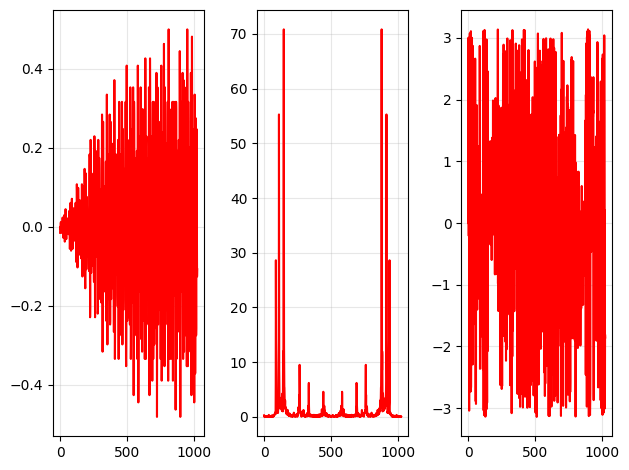

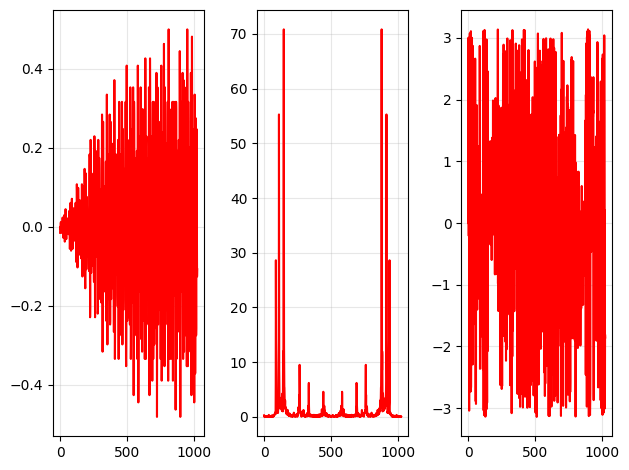

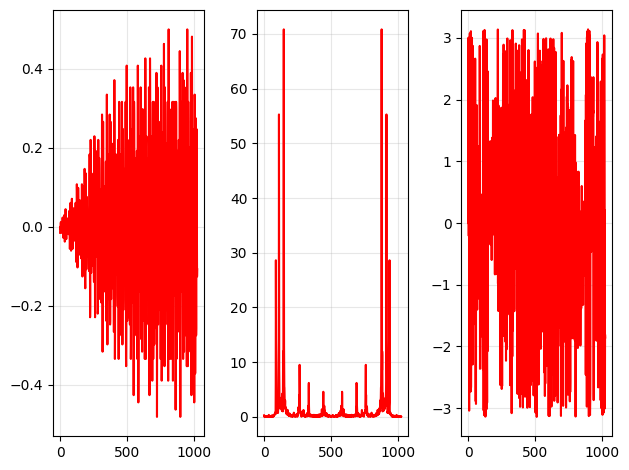

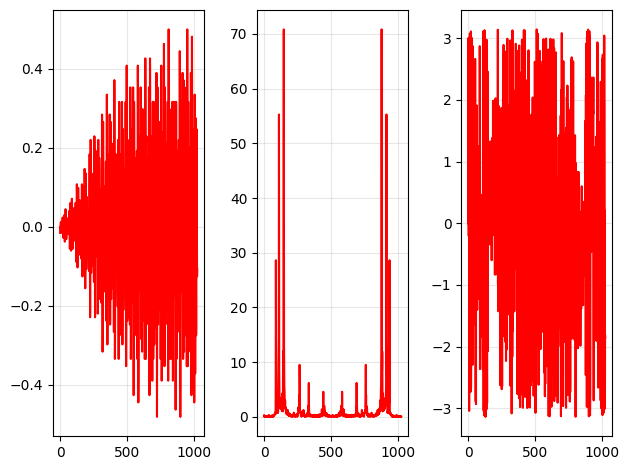

In [19]:
Y1mag = COMPLEXmagnitude(Y1) # Modulo da DFT
Y1pha = COMPLEXphase(Y1) # Fase da DFT

Y2mag = COMPLEXmagnitude(Y2) # Modulo da DFT
Y2pha = COMPLEXphase(Y2) # Fase da DFT

Y3mag = COMPLEXmagnitude(Y3) # Modulo da DFT
Y3pha = COMPLEXphase(Y3) # Fase da DFT

Y4mag = COMPLEXmagnitude(Y4) # Modulo da DFT
Y4pha = COMPLEXphase(Y4) # Fase da DFT

fig, ax = plt.subplots(1, 3)
ax[0].plot(y, 'r')
ax[1].plot(Y1mag, 'r')
ax[2].plot(Y1pha, 'r')
figureFormat(ax, fig, tight=True)
plt.show()

fig, ax = plt.subplots(1, 3)
ax[0].plot(y, 'r')
ax[1].plot(Y2mag, 'r')
ax[2].plot(Y2pha, 'r')
figureFormat(ax, fig, tight=True)
plt.show()

fig, ax = plt.subplots(1, 3)
ax[0].plot(y, 'r')
ax[1].plot(Y3mag, 'r')
ax[2].plot(Y3pha, 'r')
figureFormat(ax, fig, tight=True)
plt.show()

fig, ax = plt.subplots(1, 3)
ax[0].plot(y, 'r')
ax[1].plot(Y4mag, 'r')
ax[2].plot(Y4pha, 'r')
figureFormat(ax, fig, tight=True)
plt.show()


## Synthesis (signal reconstruction)

float64


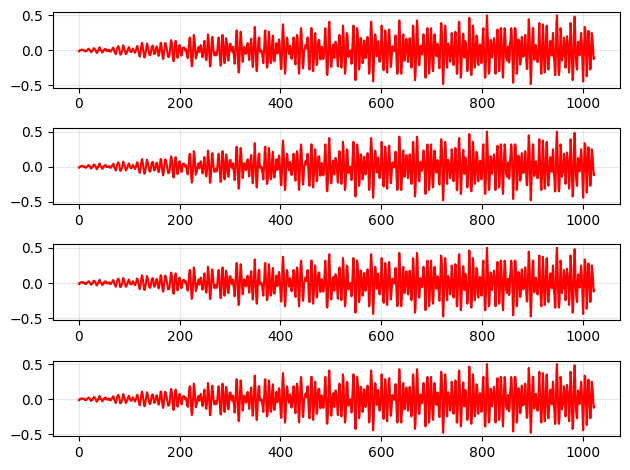

In [20]:
y1 = myIDFT(Y1, 'signal') # sinal reconstruido
y2 = myIDFT(Y2, 'basis') # sinal reconstruido
y3 = myIDFT(Y3, 'matrix') # sinal reconstruido
# y4 = myIDFT(Y4, 'ifft')

print(y1.dtype)

fig, ax = plt.subplots(4, 1)
ax[0].plot(y, 'r')
ax[1].plot(y1, 'r')
ax[2].plot(y2, 'r')
ax[3].plot(y3, 'r')
# ax[4].plot(y4, 'r')
# ax[0].set_ylim([-1, 1])
# ax[1].set_ylim([-1, 1])
figureFormat(ax, fig, tight=True)
plt.show()

Opa, precisamos apenas da metade da informacao das frequencias *DO ESPECTRO*

Plote a metade do espectro do sinal

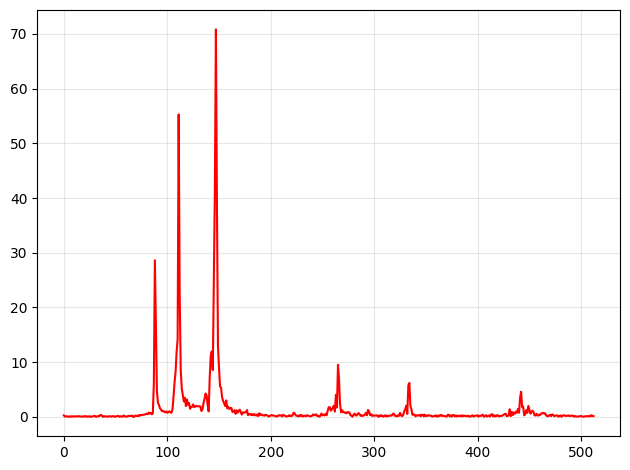

In [21]:
N = len(Y1mag)

fig, ax = plt.subplots()
ax.plot(Y1mag[:N//2 + 1], 'r')
figureFormat(ax, fig, tight=True)
plt.show()

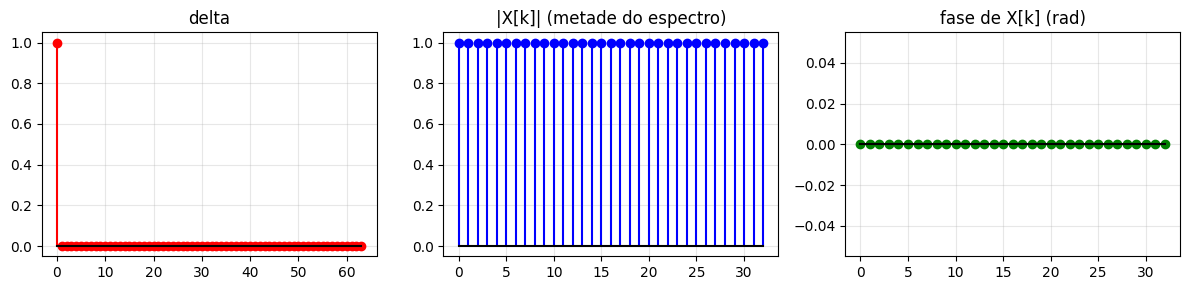

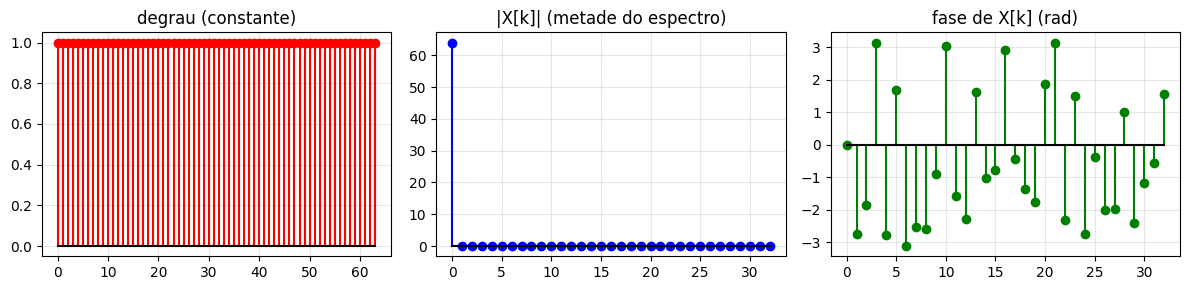

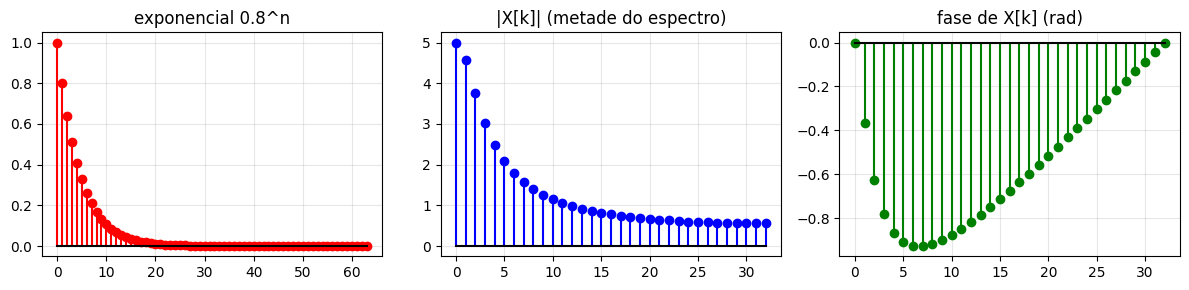

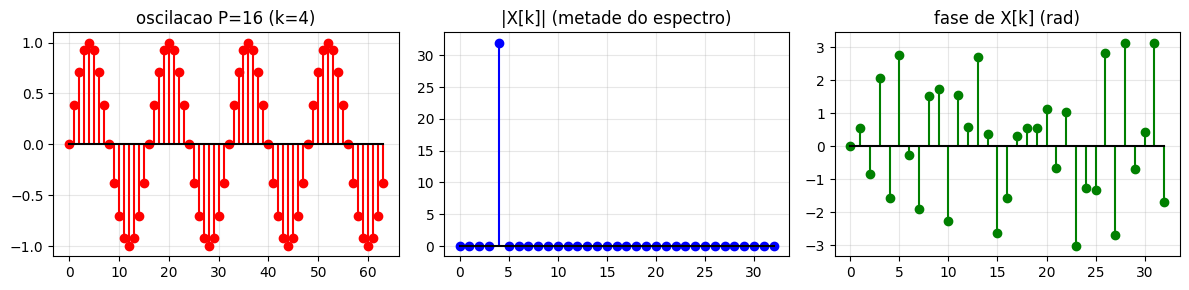

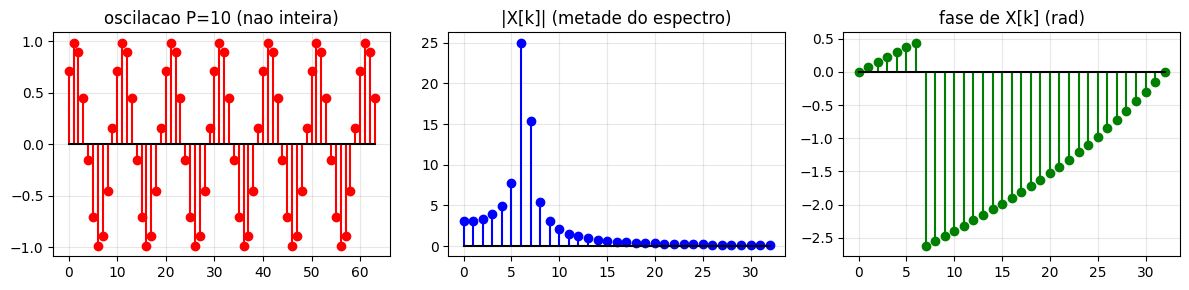

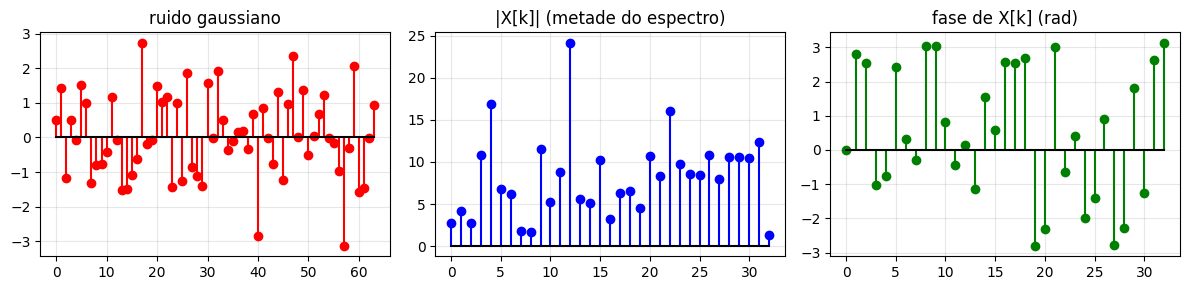

In [22]:
# Plots da DFT para os sinais basicos
def plotDFT(n, s, title):
    S = myDFT(s, 'v3')
    N = len(S)
    assert np.allclose(S, np.fft.fft(s)) # confere com a FFT do numpy
    fig, ax = plt.subplots(1, 3, figsize=(12, 3))
    ax[0].stem(n, s, linefmt='r-', markerfmt='ro', basefmt='k-')
    ax[0].set_title(title)
    ax[1].stem(np.arange(N//2 + 1), COMPLEXmagnitude(S)[:N//2 + 1],
               linefmt='b-', markerfmt='bo', basefmt='k-')
    ax[1].set_title('|X[k]| (metade do espectro)')
    ax[2].stem(np.arange(N//2 + 1), COMPLEXphase(S)[:N//2 + 1],
               linefmt='g-', markerfmt='go', basefmt='k-')
    ax[2].set_title('fase de X[k] (rad)')
    figureFormat(ax, fig, tight=True)
    plt.show()

N = 64
for sig, params, title in [('delta', None, 'delta'),
                           ('step', None, 'degrau (constante)'),
                           ('exp', None, 'exponencial 0.8^n'),
                           ('osc', {'P': 16}, 'oscilacao P=16 (k=4)'),
                           ('osc', {'P': 10, 'phi': np.pi/4}, 'oscilacao P=10 (nao inteira)'),
                           ('random', None, 'ruido gaussiano')]:
    n_, s_ = SIGNALgenerate(N, sig, params)
    plotDFT(n_, s_, title)

In [23]:
# Conferencia: todas as versoes da DFT/IDFT contra o numpy
for Yi in (Y1, Y2, Y3, Y4, Y5):
    print(np.allclose(Yi, np.fft.fft(y)), end=' ')
print()
for v in ('signal', 'basis', 'matrix', 'v4', 'ifft'):
    print(v, np.allclose(myIDFT(Y4, v), y))

True True True True True 
signal True
basis True
matrix True
v4 True
ifft True


Desafio dado em aula

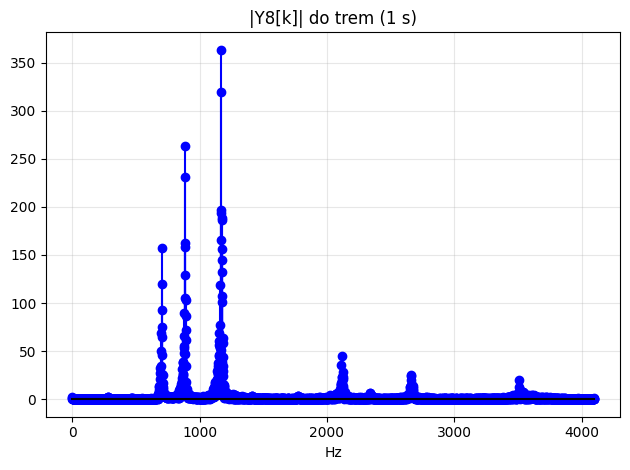

In [49]:
y8 = x[:8192]                        # 8192 = 2^13, potência de 2 (1 s de áudio)
Y8 = myDFT(y8, 'fft')                # DFT pela FFT própria

N8 = len(y8)
freqs8 = np.arange(N8) * fs / N8     # Hz de cada bin (resolução fs/N8 = 1 Hz)

fig, ax = plt.subplots()
ax.stem(freqs8[:N8//2 + 1], COMPLEXmagnitude(Y8)[:N8//2 + 1],
        linefmt='b-', markerfmt='bo', basefmt='k-')
ax.set_xlabel('Hz')
ax.set_title('|Y8[k]| do trem (1 s)')
figureFormat(ax, fig, tight=True)
plt.show()


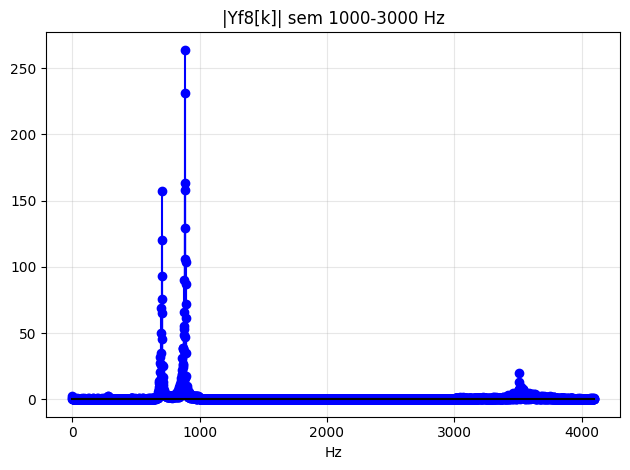

In [53]:
f_lo, f_hi = 1000, 3000              # faixa a apagar (Hz)

klo = int(round(f_lo * N8 / fs))     # 1000
khi = int(round(f_hi * N8 / fs))     # 2000

Yf8 = Y8.copy()
Yf8[klo:khi + 1] = 0                 # faixa positiva
Yf8[N8 - khi:N8 - klo + 1] = 0       # espelho

yf8 = myIDFT(Yf8, 'v4')

fig, ax = plt.subplots()
ax.stem(freqs8[:N8//2 + 1], COMPLEXmagnitude(Yf8)[:N8//2 + 1],
        linefmt='b-', markerfmt='bo', basefmt='k-')
ax.set_xlabel('Hz')
ax.set_title(f'|Yf8[k]| sem {f_lo}-{f_hi} Hz')
figureFormat(ax, fig, tight=True)
plt.show()

play(yf8, fs)
